Check Dataset

In [1]:
from pathlib import Path

dataset_path = Path("D:\\UOM\\Sem 5\\Pattern\\Assignment03\\RocogniX_Classification_Assignment\\split")

for split in ["train", "validation", "test"]:
    folder = dataset_path / split

    files = list(folder.rglob("*.pgm"))

    print(f"{split}: {len(files)} images")

    print("Example files:")
    for f in files[:5]:
        print("  ", f)

    print()

train: 436 images
Example files:
   D:\UOM\Sem 5\Pattern\Assignment03\RocogniX_Classification_Assignment\split\train\an2i_left_happy_open_2.pgm
   D:\UOM\Sem 5\Pattern\Assignment03\RocogniX_Classification_Assignment\split\train\an2i_left_happy_sunglasses_2.pgm
   D:\UOM\Sem 5\Pattern\Assignment03\RocogniX_Classification_Assignment\split\train\an2i_left_neutral_open_2.pgm
   D:\UOM\Sem 5\Pattern\Assignment03\RocogniX_Classification_Assignment\split\train\an2i_left_neutral_sunglasses_2.pgm
   D:\UOM\Sem 5\Pattern\Assignment03\RocogniX_Classification_Assignment\split\train\an2i_left_sad_sunglasses_2.pgm

validation: 93 images
Example files:
   D:\UOM\Sem 5\Pattern\Assignment03\RocogniX_Classification_Assignment\split\validation\an2i_left_angry_open_2.pgm
   D:\UOM\Sem 5\Pattern\Assignment03\RocogniX_Classification_Assignment\split\validation\an2i_left_angry_sunglasses_2.pgm
   D:\UOM\Sem 5\Pattern\Assignment03\RocogniX_Classification_Assignment\split\validation\an2i_right_angry_sunglasses

In [2]:
from PIL import Image

for split in ["train", "validation", "test"]:

    files = list((dataset_path / split).rglob("*.pgm"))

    print(f"\n{split}")

    for f in files[:5]:
        img = Image.open(f)
        print(f.name, "→", img.size, img.mode)


train
an2i_left_happy_open_2.pgm → (64, 60) L
an2i_left_happy_sunglasses_2.pgm → (64, 60) L
an2i_left_neutral_open_2.pgm → (64, 60) L
an2i_left_neutral_sunglasses_2.pgm → (64, 60) L
an2i_left_sad_sunglasses_2.pgm → (64, 60) L

validation
an2i_left_angry_open_2.pgm → (64, 60) L
an2i_left_angry_sunglasses_2.pgm → (64, 60) L
an2i_right_angry_sunglasses_2.pgm → (64, 60) L
an2i_right_happy_sunglasses_2.pgm → (64, 60) L
an2i_up_neutral_sunglasses_2.pgm → (64, 60) L

test
an2i_left_sad_open_2.pgm → (64, 60) L
an2i_up_angry_sunglasses_2.pgm → (64, 60) L
an2i_up_happy_sunglasses_2.pgm → (64, 60) L
an2i_up_sad_open_2.pgm → (64, 60) L
at33_left_angry_open_2.pgm → (64, 60) L


In [3]:
from collections import Counter

poses = ["straight", "left", "right", "up"]

for split in ["train", "validation", "test"]:

    files = list((dataset_path / split).rglob("*.pgm"))

    counts = Counter()

    for f in files:
        parts = f.stem.split("_")

        # filename:
        # userid_pose_expression_eyes_scale
        pose = parts[1]

        counts[pose] += 1

    print(f"\n{split}:")
    
    for pose in poses:
        print(f"{pose:8s}: {counts[pose]}")


train:
straight: 109
left    : 105
right   : 113
up      : 109

validation:
straight: 26
left    : 25
right   : 23
up      : 19

test:
straight: 21
left    : 27
right   : 19
up      : 28


Load Dataset into NumPy

In [4]:
from pathlib import Path
from PIL import Image
import numpy as np

# Dataset path
DATASET_PATH = Path("../split")

# Class mapping
CLASS_TO_INDEX = {
    "straight": 0,
    "left": 1,
    "right": 2,
    "up": 3
}

CLASS_NAMES = list(CLASS_TO_INDEX.keys())

def load_dataset(split):
    folder = DATASET_PATH / split

    images = []
    labels = []

    files = sorted(folder.glob("*.pgm"))

    for file in files:
        # Extract pose from filename
        # Example: an2i_left_happy_open_2.pgm
        pose = file.stem.split("_")[1]

        # Convert pose to numerical label
        label = CLASS_TO_INDEX[pose]

        # Load grayscale image
        image = np.array(Image.open(file), dtype=np.float32)

        # Normalize pixels: 0-255 -> 0-1
        image /= 255.0

        # Add channel dimension: (60,64) -> (60,64,1)
        image = np.expand_dims(image, axis=-1)

        images.append(image)
        labels.append(label)

    return np.array(images, dtype=np.float32), np.array(labels, dtype=np.int64)

In [5]:
# Load datasets
X_train, y_train = load_dataset("train")
X_val, y_val = load_dataset("validation")
X_test, y_test = load_dataset("test")


# Display information
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_val:  ", X_val.shape)
print("y_val:  ", y_val.shape)

print("X_test: ", X_test.shape)
print("y_test: ", y_test.shape)

print("\nPixel range:", X_train.min(), "to", X_train.max())
print("Classes:", CLASS_TO_INDEX)

X_train: (436, 60, 64, 1)
y_train: (436,)
X_val:   (93, 60, 64, 1)
y_val:   (93,)
X_test:  (95, 60, 64, 1)
y_test:  (95,)

Pixel range: 0.0 to 0.9882353
Classes: {'straight': 0, 'left': 1, 'right': 2, 'up': 3}


In [6]:
import os
print(os.getcwd())
print("Dataset path:", DATASET_PATH)

d:\UOM\Sem 5\Pattern\Assignment03\RocogniX_Classification_Assignment\Model_B
Dataset path: ..\split


Visualise the loaded data

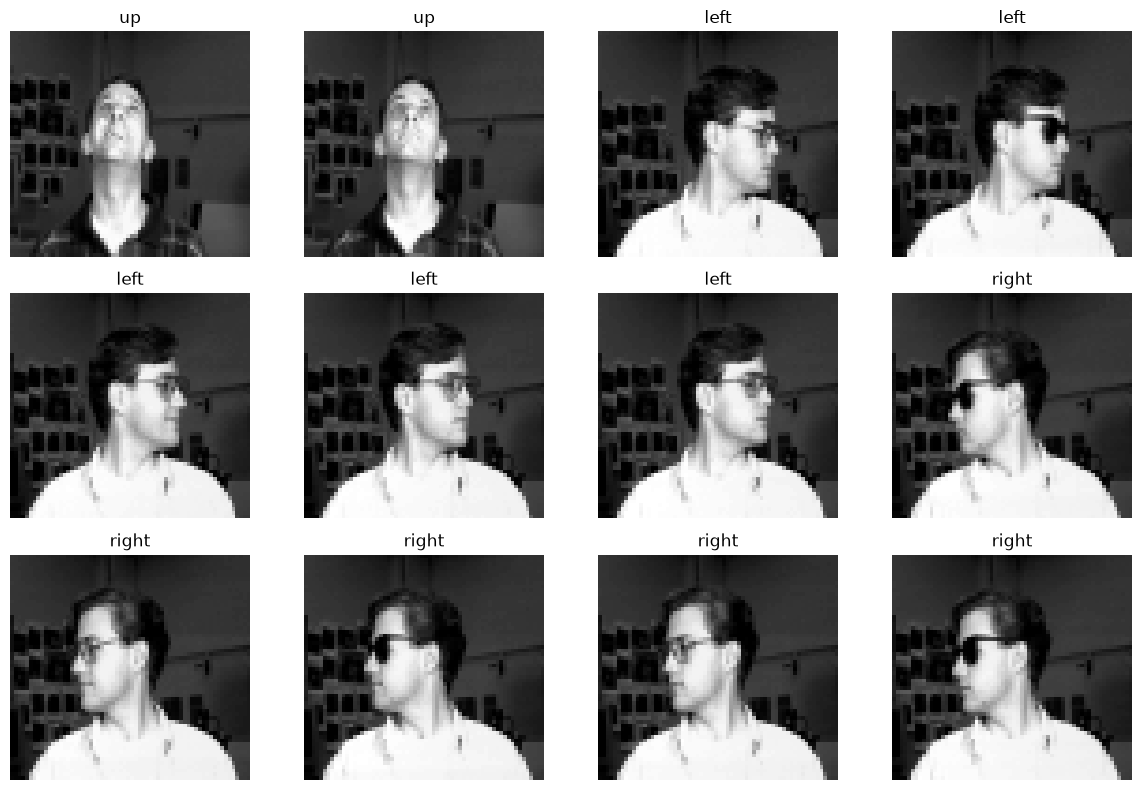

In [7]:
import matplotlib.pyplot as plt

# Number of images to display
num_images = 12
start_image_index = 60  # Starting index for displaying images

plt.figure(figsize=(12, 8))

for i in range(num_images):
    plt.subplot(3, 4, i + 1)

    plt.imshow(X_train[i+start_image_index].squeeze(), cmap="gray")
    plt.title(CLASS_NAMES[y_train[i+start_image_index]])
    plt.axis("off")

plt.tight_layout()
plt.show()

Model B Implementation

In [26]:
import tensorflow as tf
from tensorflow.keras import layers, models

# Input shape
input_shape = (60, 64, 1)

model_B = models.Sequential([
    
    # Input
    layers.Input(shape=input_shape),

    # Block 1
    layers.SeparableConv2D(32, (3, 3), padding="same", activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Block 2
    layers.SeparableConv2D(64, (3, 3), padding="same", activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Block 3
    layers.SeparableConv2D(128, (3, 3), padding="same", activation="relu"),

    # Reduce feature maps to 128 values
    layers.GlobalAveragePooling2D(),

    # Fully connected layer
    layers.Dense(64, activation="relu"),

    # Output layer
    layers.Dense(4, activation="softmax")
])

model_B.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ separable_conv2d_7              │ (None, 60, 64, 32)     │            73 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 30, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d_8              │ (None, 30, 32, 64)     │         2,400 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 15, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d_9              │ (None, 15, 16, 128)    │         8,896 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,885 (77.68 KB)

 Trainable params: 19,885 (77.68 KB)

 Non-trainable params: 0 (0.00 B)

Compile Model B

In [27]:
from tensorflow.keras.optimizers import Adam

model_B.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model_B.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ separable_conv2d_7              │ (None, 60, 64, 32)     │            73 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 30, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d_8              │ (None, 30, 32, 64)     │         2,400 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 15, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d_9              │ (None, 15, 16, 128)    │         8,896 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,885 (77.68 KB)

 Trainable params: 19,885 (77.68 KB)

 Non-trainable params: 0 (0.00 B)

Train Model B

In [36]:
history_B = model_B.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=50,
    batch_size=32,
    verbose=1
)

Epoch 1/50
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.3876 - loss: 1.2699 - val_accuracy: 0.3441 - val_loss: 1.2813
Epoch 2/50
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.4174 - loss: 1.2526 - val_accuracy: 0.3763 - val_loss: 1.2588
Epoch 3/50
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.4220 - loss: 1.2335 - val_accuracy: 0.3871 - val_loss: 1.2358
Epoch 4/50
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.4220 - loss: 1.2082 - val_accuracy: 0.4086 - val_loss: 1.2166
Epoch 5/50
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.4128 - loss: 1.1893 - val_accuracy: 0.4086 - val_loss: 1.1929
Epoch 6/50
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.4404 - loss: 1.1640 - val_accuracy: 0.4086 - val_loss: 1.1758
Epoch 7/50
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.4564 - loss: 1.1475 - val_accuracy: 0.4516 - val_loss: 1.1580
Epoch 8/50
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.4610 - loss: 1.1254 - val_accuracy: 0.4516 - v

Plat model Performance

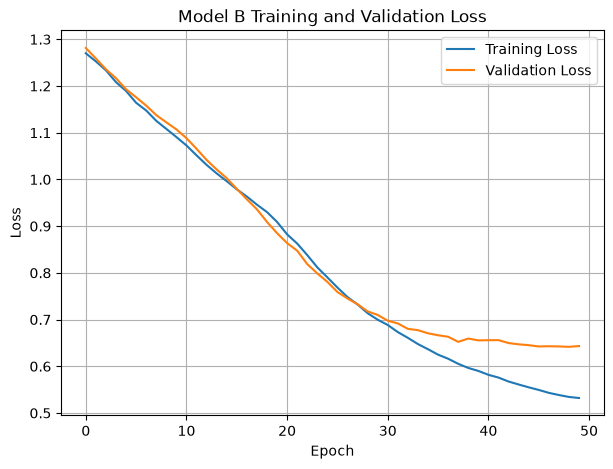

In [37]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7,5))
plt.plot(history_B.history["loss"], label="Training Loss")
plt.plot(history_B.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Model B Training and Validation Loss")
plt.legend()
plt.grid()
plt.show()

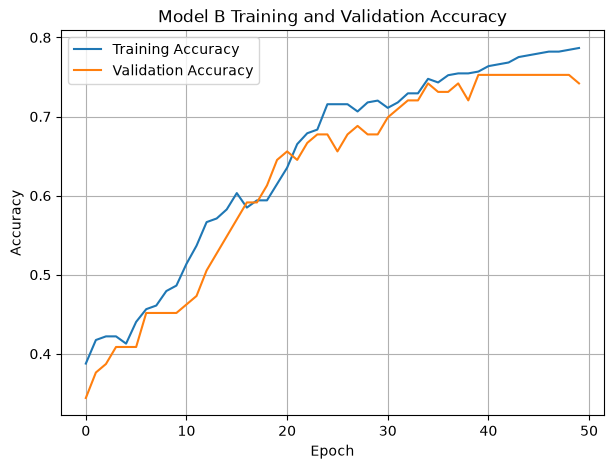

In [38]:
plt.figure(figsize=(7,5))
plt.plot(history_B.history["accuracy"], label="Training Accuracy")
plt.plot(history_B.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Model B Training and Validation Accuracy")
plt.legend()
plt.grid()
plt.show()

Evaluate model B on test set

In [39]:
test_loss, test_accuracy = model_B.evaluate(
    X_test, y_test,
    verbose=1
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Accuracy: {test_accuracy*100:.2f}%")

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.7158 - loss: 0.7423
Test Loss: 0.7423
Test Accuracy: 0.7158
Test Accuracy: 71.58%


In [40]:
# Genarate Predictions
y_pred_prob = model_B.predict(X_test)
y_pred = np.argmax(y_pred_prob, axis=1)

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step


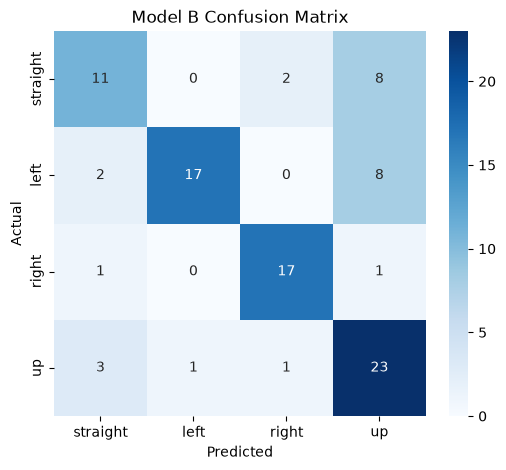

In [41]:
from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Model B Confusion Matrix")
plt.show()

In [42]:
print(classification_report(
    y_test,
    y_pred,
    target_names=CLASS_NAMES,
    digits=4
))

              precision    recall  f1-score   support

    straight     0.6471    0.5238    0.5789        21
        left     0.9444    0.6296    0.7556        27
       right     0.8500    0.8947    0.8718        19
          up     0.5750    0.8214    0.6765        28

    accuracy                         0.7158        95
   macro avg     0.7541    0.7174    0.7207        95
weighted avg     0.7509    0.7158    0.7165        95



Change ModelB2

In [52]:
from tensorflow.keras import layers, models

model_B2 = models.Sequential([
    layers.Input(shape=(60, 64, 1)),

    layers.SeparableConv2D(32, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(2),

    layers.SeparableConv2D(64, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(2),

    layers.SeparableConv2D(128, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(2),

    layers.SeparableConv2D(192, 3, padding="same", activation="relu"),

    layers.GlobalAveragePooling2D(),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(4, activation="softmax")
])

model_B2.summary()
print("Total parameters:", model_B2.count_params())


from tensorflow.keras.optimizers import Adam

model_B2.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)




history_B2 = model_B2.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=50,
    batch_size=32,
    verbose=1
)



Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ separable_conv2d_30             │ (None, 60, 64, 32)     │            73 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_22 (MaxPooling2D) │ (None, 30, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d_31             │ (None, 30, 32, 64)     │         2,400 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_23 (MaxPooling2D) │ (None, 15, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d_32             │ (None, 15, 16, 128)    │         8,896 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_24 (MaxPooling2D) │ (None, 7, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d_33             │ (None, 7, 8, 192)      │        25,920 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_8      │ (None, 192)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 128)            │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 62,509 (244.18 KB)

 Trainable params: 62,509 (244.18 KB)

 Non-trainable params: 0 (0.00 B)

Total parameters: 62509
Epoch 1/50
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 50ms/step - accuracy: 0.2179 - loss: 1.3866 - val_accuracy: 0.2796 - val_loss: 1.3852
Epoch 2/50
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.2798 - loss: 1.3864 - val_accuracy: 0.2473 - val_loss: 1.3856
Epoch 3/50
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.2638 - loss: 1.3864 - val_accuracy: 0.2473 - val_loss: 1.3862
Epoch 4/50
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.2661 - loss: 1.3861 - val_accuracy: 0.2473 - val_loss: 1.3866
Epoch 5/50
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.2683 - loss: 1.3860 - val_accuracy: 0.2473 - val_loss: 1.3871
Epoch 6/50
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.2500 - loss: 1.3865 - val_accuracy: 0.2473 - val_loss: 1.3872
Epoch 7/50
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.2638 - loss: 1.3861 - val_accuracy: 0.2473 - val_loss: 1.3874
Epoch 8/50
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.2477 - loss: 1.3867 - 

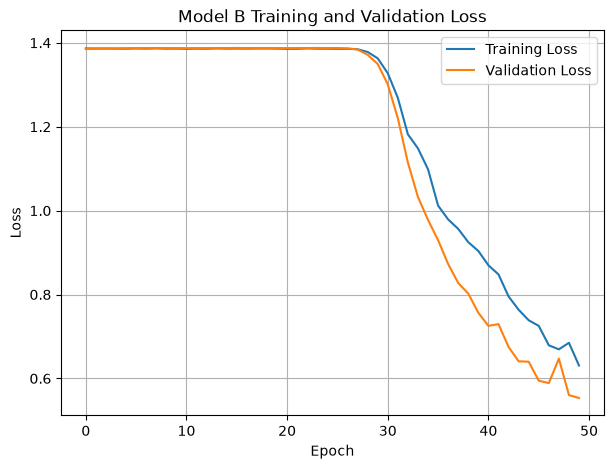

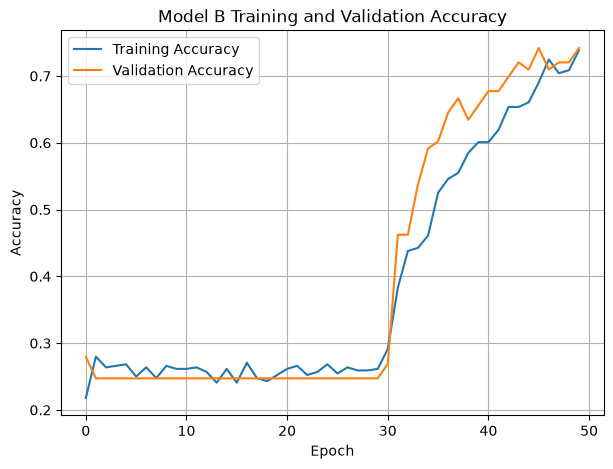

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.6526 - loss: 0.8045
Test Loss: 0.8045
Test Accuracy: 0.6526
Test Accuracy: 65.26%
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step


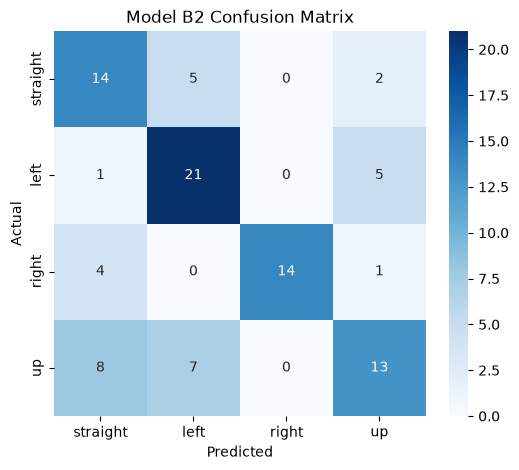

              precision    recall  f1-score   support

    straight     0.5185    0.6667    0.5833        21
        left     0.6364    0.7778    0.7000        27
       right     1.0000    0.7368    0.8485        19
          up     0.6190    0.4643    0.5306        28

    accuracy                         0.6526        95
   macro avg     0.6935    0.6614    0.6656        95
weighted avg     0.6779    0.6526    0.6540        95



In [53]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7,5))
plt.plot(history_B2.history["loss"], label="Training Loss")
plt.plot(history_B2.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Model B Training and Validation Loss")
plt.legend()
plt.grid()
plt.show()


plt.figure(figsize=(7,5))
plt.plot(history_B2.history["accuracy"], label="Training Accuracy")
plt.plot(history_B2.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Model B Training and Validation Accuracy")
plt.legend()
plt.grid()
plt.show()


test_loss2, test_accuracy2 = model_B2.evaluate(
    X_test, y_test,
    verbose=1
)

print(f"Test Loss: {test_loss2:.4f}")
print(f"Test Accuracy: {test_accuracy2:.4f}")
print(f"Test Accuracy: {test_accuracy2*100:.2f}%")


# Genarate Predictions
y_pred_prob2 = model_B2.predict(X_test)
y_pred2 = np.argmax(y_pred_prob2, axis=1)

from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test, y_pred2)

plt.figure(figsize=(6,5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Model B2 Confusion Matrix")
plt.show()

print(classification_report(
    y_test,
    y_pred2,
    target_names=CLASS_NAMES,
    digits=4
))

